# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Siti Indriani
- **Email:** 2406068@itg.ac.id
- **ID Dicoding:** DS367B6X1670

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Berapa perbedaan rata-rata jumlah penyewaan sepeda per jam antara hari kerja dan akhir pekan/libur, serta pada jam berapa permintaan mencapai puncaknya selama periode 2011-2012?
- **Pertanyaan 2:** Bagaimana perbedaan rata-rata jumlah penyewaan sepeda per jam pada setiap kondisi cuaca, serta kondisi cuaca mana yang menghasilkan rata-rata permintaan tertinggi dan terendah selama periode 2011–2012?

## Import Semua Packages/Library yang Digunakan

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile

In [25]:
import zipfile

# Buka file ZIP dan ekstrak semua isinya ke folder saat ini
with zipfile.ZipFile("Bike-sharing-dataset.zip", "r") as zip_ref:
    zip_ref.extractall(".")

print("File berhasil diekstrak!")

File berhasil diekstrak!


## Data Wrangling

### Gathering Data

In [26]:
# Extract and read a specific file from the ZIP archive
with zipfile.ZipFile("Bike-sharing-dataset.zip", "r") as zip_ref:
    # You can choose 'day.csv' or 'hour.csv'
    with zip_ref.open("day.csv") as file:
        customers_df = pd.read_csv(file)

customers_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


#### Load df ...

In [27]:
import pandas as pd

# Load data harian dari Bike Sharing Dataset
day_df = pd.read_csv("day.csv")

# Menampilkan 5 baris pertama
day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [28]:
import pandas as pd

# Load data harian dari Bike Sharing Dataset
hour_df = pd.read_csv("hour.csv")

# Menampilkan 5 baris pertama
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:** (Opsional)
- Dataset day_df berisi informasi peminjaman sepeda harian yang mencakup variabel tanggal (dteday), cuaca (weathersit), suhu (temp), kelembapan (hum), kecepatan angin (windspeed), hingga jumlah pengguna casual, terdaftar (registered), dan total peminjaman (cnt).
- Pada 5 baris pertama data awal (Januari 2011), mayoritas pengguna sepeda adalah pengguna terdaftar (registered users) dibandingkan pengguna biasa (casual users). Sebagai contoh, pada tanggal 1 Januari 2011, terdapat 654 pengguna terdaftar dan 331 pengguna casual.
- Total penyewaan sepeda harian (cnt) di awal bulan Januari berkisar antara 801 hingga 1.600 peminjaman per hari.
- Dataset hour_df mencatat peminjaman sepeda secara rinci tiap jam, yang ditunjukkan oleh adanya kolom tambahan hr (bernilai 0 hingga 4 pada 5 baris pertama).
- Pada dini hari (pukul 00.00 hingga 04.00 di tanggal 1 Januari 2011), volume peminjaman sepeda (cnt) relatif sangat rendah, berkisar antara 1 hingga 40 peminjaman per jam.
- Peminjaman terendah pada sampel data ini terjadi pada pukul 04.00 pagi (hr = 4) dengan total hanya 1 peminjaman (cnt = 1).
- Sebagian besar pengguna pada jam-jam dini hari ini tetap didominasi oleh pengguna terdaftar (registered) dibandingkan pengguna biasa (casual).  


### Assessing Data

#### Identifying ... problem

In [29]:
day_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


**Steps to Take:**
- Mengubah tipe data pada kolom dteday dari object menjadi datetime agar dapat diproses sebagai variabel tanggal.
- Memeriksa dan memastikan tidak ada data bernilai missing/null (seluruh 16 kolom memiliki 731 nilai non-null).
- Memeriksa keberadaan data duplikat menggunakan day_df.duplicated().sum() pada tahap cleansing data.

**Insight:** (Opsional)
- Dataset day_df terdiri dari 731 baris entitas data dan 16 kolom.   Tidak terdeteksi adanya nilai yang hilang (missing values) pada seluruh kolom karena semua kolom memiliki jumlah data 731 non-null.
- Terdapat kesalahan tipe data (data type mismatch) pada kolom dteday yang terbaca sebagai tipe object (string), padahal seharusnya bernilai datetime.

### Cleaning Data

#### Fixing ... problem

In [30]:
# 1. Mengubah tipe data kolom dteday menjadi datetime
day_df["dteday"] = pd.to_datetime(day_df["dteday"])

# 2. Memeriksa kembali tipe data untuk memastikan perubahan berhasil
day_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     731 non-null    int64         
 1   dteday      731 non-null    datetime64[ns]
 2   season      731 non-null    int64         
 3   yr          731 non-null    int64         
 4   mnth        731 non-null    int64         
 5   holiday     731 non-null    int64         
 6   weekday     731 non-null    int64         
 7   workingday  731 non-null    int64         
 8   weathersit  731 non-null    int64         
 9   temp        731 non-null    float64       
 10  atemp       731 non-null    float64       
 11  hum         731 non-null    float64       
 12  windspeed   731 non-null    float64       
 13  casual      731 non-null    int64         
 14  registered  731 non-null    int64         
 15  cnt         731 non-null    int64         
dtypes: datetime64[ns](1), floa

In [31]:
day_df.isna().sum()

,0
instant,0
dteday,0
season,0
yr,0
mnth,0
holiday,0
weekday,0
workingday,0
weathersit,0
temp,0


In [32]:
print("Jumlah duplikasi: ", day_df.duplicated().sum())

Jumlah duplikasi:  0


In [33]:
day_df.describe()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2012-01-01 00:00:00,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
min,1.000000,2011-01-01 00:00:00,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2011-07-02 12:00:00,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,2012-01-01 00:00:00,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,2012-07-01 12:00:00,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,2012-12-31 00:00:00,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000
std,211.165812,NaN,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452


In [34]:
# 1. Mengubah tipe data kolom dteday menjadi datetime
hour_df["dteday"] = pd.to_datetime(hour_df["dteday"])

# 2. Memeriksa kembali tipe data untuk memastikan perubahan berhasil
hour_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     17379 non-null  int64         
 1   dteday      17379 non-null  datetime64[ns]
 2   season      17379 non-null  int64         
 3   yr          17379 non-null  int64         
 4   mnth        17379 non-null  int64         
 5   hr          17379 non-null  int64         
 6   holiday     17379 non-null  int64         
 7   weekday     17379 non-null  int64         
 8   workingday  17379 non-null  int64         
 9   weathersit  17379 non-null  int64         
 10  temp        17379 non-null  float64       
 11  atemp       17379 non-null  float64       
 12  hum         17379 non-null  float64       
 13  windspeed   17379 non-null  float64       
 14  casual      17379 non-null  int64         
 15  registered  17379 non-null  int64         
 16  cnt         17379 non-

In [35]:
print("Jumlah duplikasi: ",hour_df.duplicated().sum())
hour_df.describe()

Jumlah duplikasi:  0


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2012-01-02 04:08:34.552045568,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
min,1.0000,2011-01-01 00:00:00,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2011-07-04 00:00:00,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,2012-01-02 00:00:00,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,2012-07-02 00:00:00,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,2012-12-31 00:00:00,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000
std,5017.0295,NaN,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599


In [36]:
day_df.drop_duplicates(inplace=True)

In [37]:
print("Jumlah duplikasi: ", day_df.duplicated().sum())

Jumlah duplikasi:  0


In [38]:
hour_df.drop_duplicates(inplace=True)

In [39]:
print("Jumlah duplikasi: ", hour_df.duplicated().sum())

Jumlah duplikasi:  0


**Insight:** (Opsional)
1. Insight & Steps to Take untuk Data Harian (day_df)
- Insight:Dataset day_df berisi 731 entri harian tanpa adanya missing values (0 data kosong).
- Tipe data kolom dteday telah berhasil diperbaiki dari object menjadi datetime64[ns].
- Rata-rata total peminjaman sepeda harian (cnt) berada di angka 4.504 penyewaan, dengan nilai maksimum mencapai 8.714 penyewaan dalam satu hari.   Pengguna terdaftar (registered) mendominasi peminjaman harian dengan rata-rata 3.656 penyewaan per hari, dibandingkan pengguna biasa (casual) yang rata-ratanya 848 penyewaan.

Steps to Take: Melakukan eksplorasi data (Exploratory Data Analysis) untuk melihat tren peminjaman harian berdasarkan musim (season), cuaca (weathersit), dan hari kerja (workingday).

2. Insight & Steps to Take untuk Data Per Jam (hour_df)
- Insight:Dataset hour_df berisi 17.379 entri data per jam.
- Tidak ditemukan adanya data duplikat (Jumlah duplikasi: 0) maupun missing values.
- Kolom dteday pada hour_df masih bertipe data object (string).
- Rata-rata peminjaman per jam (cnt) adalah 189 penyewaan, dengan lonjakan maksimum hingga 977 penyewaan dalam 1 jam.

Steps to Take:
- Melakukan analisis jam puncak (peak hours) untuk melihat pada jam berapa peminjaman sepeda paling tinggi dan paling rendah terjadi.   

In [40]:
day_df.describe()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2012-01-01 00:00:00,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
min,1.000000,2011-01-01 00:00:00,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2011-07-02 12:00:00,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,2012-01-01 00:00:00,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,2012-07-01 12:00:00,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,2012-12-31 00:00:00,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000
std,211.165812,NaN,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452


In [41]:
hour_df.describe()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2012-01-02 04:08:34.552045568,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
min,1.0000,2011-01-01 00:00:00,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2011-07-04 00:00:00,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,2012-01-02 00:00:00,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,2012-07-02 00:00:00,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,2012-12-31 00:00:00,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000
std,5017.0295,NaN,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599


## Exploratory Data Analysis (EDA)

### Explore ...

In [42]:
day_df.describe(include="all")

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2012-01-01 00:00:00,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
min,1.000000,2011-01-01 00:00:00,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2011-07-02 12:00:00,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,2012-01-01 00:00:00,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,2012-07-01 12:00:00,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,2012-12-31 00:00:00,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000
std,211.165812,NaN,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452


In [43]:
hour_df.describe(include="all")

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2012-01-02 04:08:34.552045568,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
min,1.0000,2011-01-01 00:00:00,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2011-07-04 00:00:00,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,2012-01-02 00:00:00,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,2012-07-02 00:00:00,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,2012-12-31 00:00:00,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000
std,5017.0295,NaN,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599


1. Pengelompokan Berdasarkan Musim

In [44]:
day_df.groupby(by="season").agg({
    "instant": "count", # Jumlah hari dalam musim tersebut
    "cnt": ["max", "min", "mean", "sum"], # Statistik total peminjaman
    "casual": "sum", # Total peminjaman casual
    "registered": "sum" # Total peminjaman registered
})

instant   cnt                              casual registered
         count   max   min         mean      sum     sum        sum
season                                                             
1          181  7836   431  2604.132597   471348   60622     410726
2          184  8362   795  4992.331522   918589  203522     715067
3          188  8714  1115  5644.303191  1061129  226091     835038
4          178  8555    22  4728.162921   841613  129782     711831

2. Pengelompokan Berdasarkan Cuaca

In [45]:
# Pengelompokan berdasarkan kondisi cuaca dan diurutkan secara descending
day_df.groupby(by="weathersit").cnt.sum().sort_values(ascending=False)

,cnt
weathersit,
1,2257952
2,996858
3,37869


1. Statistik Peminjaman Berdasarkan Jam

In [46]:
hour_df.groupby(by="hr").agg({
    "instant": "count", # Jumlah catatan jam
    "cnt": ["max", "min", "mean", "sum"], # Statistik total peminjaman
    "casual": "mean", # Rata-rata peminjaman pengguna casual
    "registered": "mean" # Rata-rata peminjaman pengguna registered
})

instant  cnt                             casual  registered
     count  max min        mean     sum       mean        mean
hr                                                            
0      726  283   2   53.898072   39130  10.158402   43.739669
1      724  168   1   33.375691   24164   6.504144   26.871547
2      715  132   1   22.869930   16352   4.772028   18.097902
3      697   79   1   11.727403    8174   2.715925    9.011478
4      697   28   1    6.352941    4428   1.253945    5.098996
5      717   66   1   19.889819   14261   1.411437   18.478382
6      725  213   1   76.044138   55132   4.161379   71.882759
7      727  596   1  212.064649  154171  11.055021  201.009629
8      727  839   5  359.011004  261001  21.679505  337.331499
9      727  426  14  219.309491  159438  30.891334  188.418157
10     727  539   8  173.668501  126257  46.477304  127.191197
11     727  663  10  208.143054  151320  59.540578  148.602476
12     728  776   3  253.315934  184414  68.293956  185.021978
13     729  760  11  253.661180  184919  72.308642  181.352538
14     729  750  12  240.949246  175652  75.567901  165.381344
15     729  750   7  251.233196  183149  74.905350  176.327846
16     730  783  11  311.983562  227748  73.745205  238.238356
17     730  976  15  461.452055  336860  74.273973  387.178082
18     728  977  23  425.510989  309772  61.120879  364.390110
19     728  743  11  311.523352  226789  48.770604  262.752747
20     728  567  11  226.030220  164550  36.233516  189.796703
21     728  584   6  172.314560  125445  28.255495  144.059066
22     728  502   9  131.335165   95612  22.252747  109.082418
23     728  256   2   87.831044   63941  15.199176   72.631868

2. Mengurutkan Jam dengan Penyewaan Terbanyak

In [47]:
# Menampilkan jam dengan total peminjaman terbanyak
hour_df.groupby(by="hr").cnt.sum().sort_values(ascending=False)

,cnt
hr,
17,336860
18,309772
8,261001
16,227748
19,226789
13,184919
12,184414
15,183149
14,175652


3. Kombinasi Jam dan Hari Kerja

In [48]:
hour_df.groupby(by=["workingday", "hr"]).agg({
    "casual": "mean",
    "registered": "mean",
    "cnt": "mean"
})

casual  registered         cnt
workingday hr                                    
0          0    16.647826   74.152174   90.800000
           1    12.504348   57.004348   69.508696
           2    10.399123   42.771930   53.171053
           3     6.453744   19.321586   25.775330
           4     2.264317    6.000000    8.264317
           5     1.725225    6.963964    8.689189
           6     3.820961   14.921397   18.742358
           7     8.606061   34.800866   43.406926
           8    20.424242   85.229437  105.653680
           9    45.017316  126.606061  171.623377
           10   79.268398  176.640693  255.909091
           11  106.653680  208.662338  315.316017
           12  126.246753  240.012987  366.259740
           13  136.424242  236.307359  372.731602
           14  139.593074  225.051948  364.645022
           15  136.502165  222.311688  358.813853
           16  128.614719  224.112554  352.727273
           17  111.813853  211.735931  323.549784
           18   84.221739  196.834783  281.056522
           19   65.547826  166.126087  231.673913
           20   46.765217  127.973913  174.739130
           21   36.147826  105.913043  142.060870
           22   28.056522   88.004348  116.060870
           23   19.139130   66.791304   85.930435
1          0     7.149194   29.637097   36.786290
           1     3.710526   12.842105   16.552632
           2     2.137577    6.546201    8.683778
           3     0.910638    4.031915    4.942553
           4     0.765957    4.663830    5.429787
           5     1.270707   23.642424   24.913131
           6     4.318548   98.181452  102.500000
           7    12.195565  278.417339  290.612903
           8    22.264113  454.741935  477.006048
           9    24.312500  217.205645  241.518145
           10   31.205645  104.161290  135.366935
           11   37.598790  120.631048  158.229839
           12   41.358149  159.462777  200.820926
           13   42.568273  155.861446  198.429719
           14   45.869478  137.702811  183.572289
           15   46.333333  154.997992  201.331325
           16   48.344689  244.777555  293.122244
           17   56.895792  468.394790  525.290581
           18   50.451807  441.775100  492.226908
           19   41.022088  307.379518  348.401606
           20   31.369478  218.349398  249.718876
           21   24.610442  161.676707  186.287149
           22   19.572289  118.817269  138.389558
           23   13.379518   75.329317   88.708835

**Insight:** (Opsional)
- xxx
- xxx

## Visualization & Explanatory Analysis

### Pertanyaan 1:

Rata-rata penyewaan/jam (Hari Kerja): 193.21
Rata-rata penyewaan/jam (Akhir Pekan/Libur): 181.41
Perbedaan rata-rata: 11.80 sepeda/jam

--- 3 Jam Puncak Hari Kerja ---
    hr         cnt
35  17  525.290581
37  18  492.226908
17   8  477.006048

--- 3 Jam Puncak Akhir Pekan/Libur ---
    hr         cnt
26  13  372.731602
24  12  366.259740
28  14  364.645022


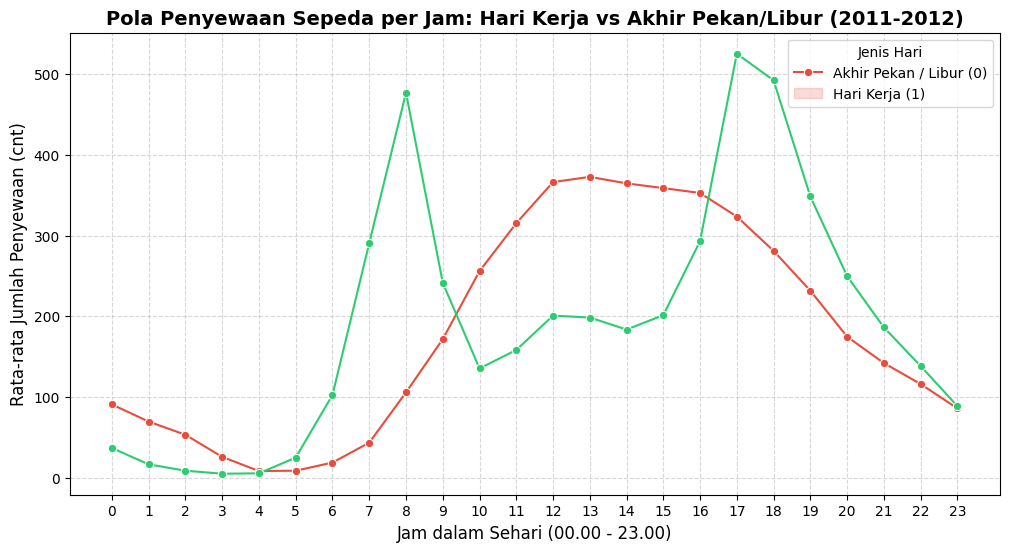

In [49]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Menghitung rata-rata penyewaan per jam (Hari Kerja vs Akhir Pekan/Libur)
workingday_avg = hour_df.groupby('workingday')['cnt'].mean()
diff_avg = workingday_avg[1] - workingday_avg[0]

print(f"Rata-rata penyewaan/jam (Hari Kerja): {workingday_avg[1]:.2f}")
print(f"Rata-rata penyewaan/jam (Akhir Pekan/Libur): {workingday_avg[0]:.2f}")
print(f"Perbedaan rata-rata: {diff_avg:.2f} sepeda/jam\n")

# 2. Agregasi rata-rata penyewaan per jam (0-23) untuk masing-masing jenis hari
hourly_pattern = hour_df.groupby(['hr', 'workingday'])['cnt'].mean().reset_index()

# Menampilkan jam dengan peminjaman tertinggi (Peak Hours)
peak_working = hourly_pattern[hourly_pattern['workingday'] == 1].sort_values(by='cnt', ascending=False).head(3)
peak_non_working = hourly_pattern[hourly_pattern['workingday'] == 0].sort_values(by='cnt', ascending=False).head(3)

print("--- 3 Jam Puncak Hari Kerja ---")
print(peak_working[['hr', 'cnt']])

print("\n--- 3 Jam Puncak Akhir Pekan/Libur ---")
print(peak_non_working[['hr', 'cnt']])

# 3. Membuat Visualisasi Tren Per Jam
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=hourly_pattern,
    x='hr',
    y='cnt',
    hue='workingday',
    palette=['#E74C3C', '#2ECC71'],
    marker='o'
)

plt.title('Pola Penyewaan Sepeda per Jam: Hari Kerja vs Akhir Pekan/Libur (2011-2012)', fontsize=14, fontweight='bold')
plt.xlabel('Jam dalam Sehari (00.00 - 23.00)', fontsize=12)
plt.ylabel('Rata-rata Jumlah Penyewaan (cnt)', fontsize=12)
plt.xticks(range(0, 24))
plt.legend(title='Jenis Hari', labels=['Akhir Pekan / Libur (0)', 'Hari Kerja (1)'])
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Pertanyaan 2:

--- Rata-Rata Penyewaan per Jam Berdasarkan Kondisi Cuaca ---
 weathersit                  weather_label        cnt
          1     1: Cerah / Berawan Sedikit 204.869272
          2             2: Kabut / Mendung 175.165493
          3 3: Hujan Ringan / Salju Ringan 111.579281
          4 4: Hujan Lebat / Badai / Salju  74.333333


/tmp/ipykernel_1166/260335085.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  barplot = sns.barplot(


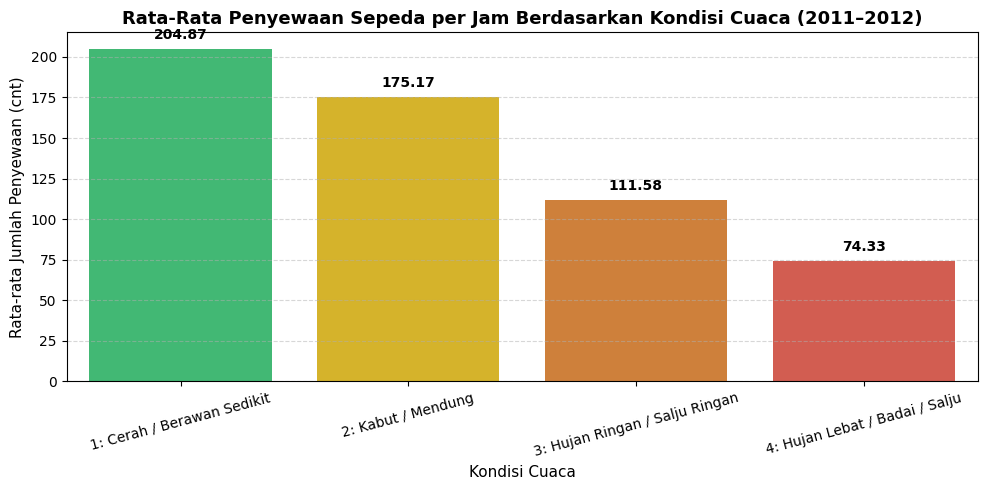

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Menghitung rata-rata penyewaan per jam untuk setiap kondisi cuaca
weather_avg = hour_df.groupby('weathersit')['cnt'].mean().reset_index()

# Pemetaan label cuaca berdasarkan dokumentasi dataset
weather_labels = {
    1: '1: Cerah / Berawan Sedikit',
    2: '2: Kabut / Mendung',
    3: '3: Hujan Ringan / Salju Ringan',
    4: '4: Hujan Lebat / Badai / Salju'
}
weather_avg['weather_label'] = weather_avg['weathersit'].map(weather_labels)

# Menampilkan tabel hasil
print("--- Rata-Rata Penyewaan per Jam Berdasarkan Kondisi Cuaca ---")
print(weather_avg[['weathersit', 'weather_label', 'cnt']].to_string(index=False))

# 2. Membuat Visualisasi Bar Chart
plt.figure(figsize=(10, 5))
colors = ['#2ECC71', '#F1C40F', '#E67E22', '#E74C3C']

barplot = sns.barplot(
    data=weather_avg,
    x='weather_label',
    y='cnt',
    palette=colors
)

plt.title('Rata-Rata Penyewaan Sepeda per Jam Berdasarkan Kondisi Cuaca (2011–2012)', fontsize=13, fontweight='bold')
plt.xlabel('Kondisi Cuaca', fontsize=11)
plt.ylabel('Rata-rata Jumlah Penyewaan (cnt)', fontsize=11)
plt.xticks(rotation=15)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Menambahkan label angka di atas setiap bar
for p in barplot.patches:
    barplot.annotate(f'{p.get_height():.2f}',
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom',
                     fontsize=10, fontweight='bold',
                     xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- xxx
- xxx

## Analisis Lanjutan (Opsional)

**Insight:** (Opsional)
- xxx
- xxx

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:**
1. Pola Mobilitas Komuter (Hari Kerja): Grafik menunjukkan lonjakan tajam yang sejajar dengan jam berangkat kerja/sekolah (08.00) dan jam pulang kerja (17.00–18.00). Pengguna dominan adalah pekerja komuter.

2. Pola Rekreasi (Akhir Pekan): Peminjaman sepeda pada akhir pekan terdistribusi secara melengkung di siang hingga sore hari, menandakan sepeda lebih banyak digunakan untuk aktivitas rekreasi, Olahraga, atau jalan-jalan santai.
- **Conclusion pertanyaan 2:** xxx
1. Sensitivitas Terhadap Cuaca: Terlihat tren penurunan yang konsisten seiring memburuknya cuaca. Pengguna sangat sensitif terhadap visibilitas dan kenyamanan berkendara.

2. Implikasi Operasional: Manajemen dapat mengurangi atau mengatur ulang jadwal pemeliharaan unit armada sepeda saat prediksi cuaca buruk (Cuaca 3 & 4), serta memaksimalkan ketersediaan unit sepeda di stasiun-stasiun populer saat cuaca cerah (Cuaca 1) untuk memenuhi lonjakan permintaan.

**Rekomendasi Action Item:**
- Manajemen Armada (Rebalancing): Fokuskan redistribusi dan ketersediaan unit sepeda di stasiun-stasiun area perkantoran/transportasi umum sebelum pukul 08.00 pagi dan 17.00 sore pada hari kerja. Pada akhir pekan, tempatkan lebih banyak armada di stasiun area taman atau tempat wisata.

- Jadwal Perawatan (Maintenance): Alokasikan jadwal pemeliharaan rutin armada pada jam-jam sepi peminjaman (dini hari pukul 00.00–05.00) atau saat prediksi cuaca menunjukkan hujan lebat (Cuaca Tipe 3 & 4).

- Strategi Pemasaran: Buat penawaran diskon/promosi khusus pengguna casual pada hari kerja di luar jam sibuk (siang hari) untuk meningkatkan efisiensi penggunaan armada yang menganggur.